In [1]:
import json
import pandas as pd

CAP = 2816
sel = json.load(open("/kaggle/input/datasets/ponishbhatia3/atp-intern-selection/selection.json"))
rows = [
    {"type": t, "source": sel["source"][q], "split": sel["split"][q], "stratum": sel["stratum"][q],
     "over_cap": sel["n_image_tokens"][q] > CAP}
    for t, ids in sel["selected"].items() for q in ids
]
df = pd.DataFrame(rows)
print(len(df), "questions,", int(df.over_cap.sum()), "over the cap")
print(df.groupby("stratum").over_cap.mean().round(3).rename("share over cap"))
print(pd.crosstab([df.type, df.source, df.split], [df.stratum, df.over_cap]))

4292 questions, 1862 over the cap
stratum
false_yes    0.432
true_no      0.421
true_yes     0.444
Name: share over cap, dtype: float64
stratum                  false_yes       true_no       true_yes      
over_cap                     False True    False True     False True 
type      source   split                                             
attribute amber    test         36    36      19    19       32    24
                   train       175   109     103    68      144   116
                   val          36    21      24    14       33    22
relation  amber    test          0     1      17    20       21    21
                   train         1     3      96    66      102    90
                   val           2     1      26    13       24    11
          reefknot test        109    79      45    41       79    57
                   train       502   403     224   154      341   290
                   val         114    90      42    38       83    55


In [2]:
!ls /kaggle/input/datasets/*

/kaggle/input/datasets/nocturnalnerd18:
amber-hallucination  dla-intern  vlm-questions

/kaggle/input/datasets/ponishbhatia3:
atp-intern-selection

/kaggle/input/datasets/sajjad2goudarzi:
the-visual-genome-dataset


In [3]:
!kaggle datasets status ponishbhatia3/atp-intern-selection

ready

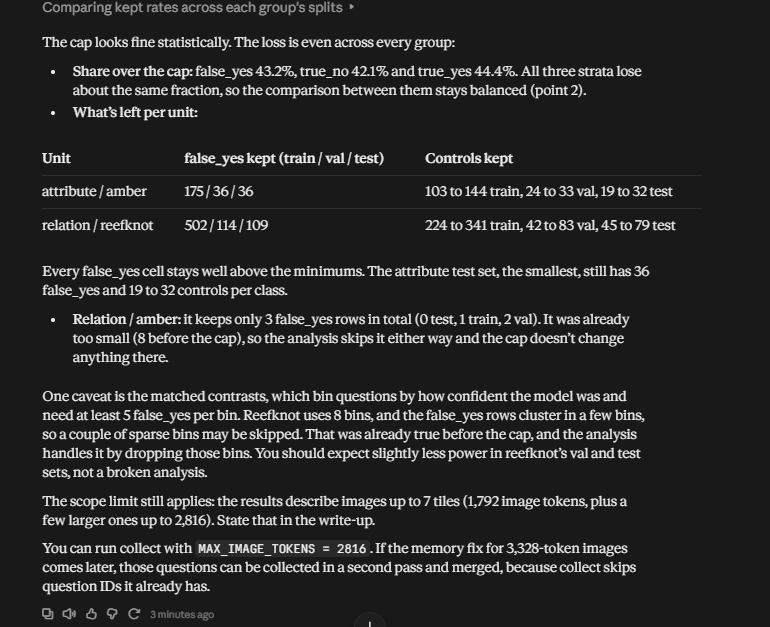

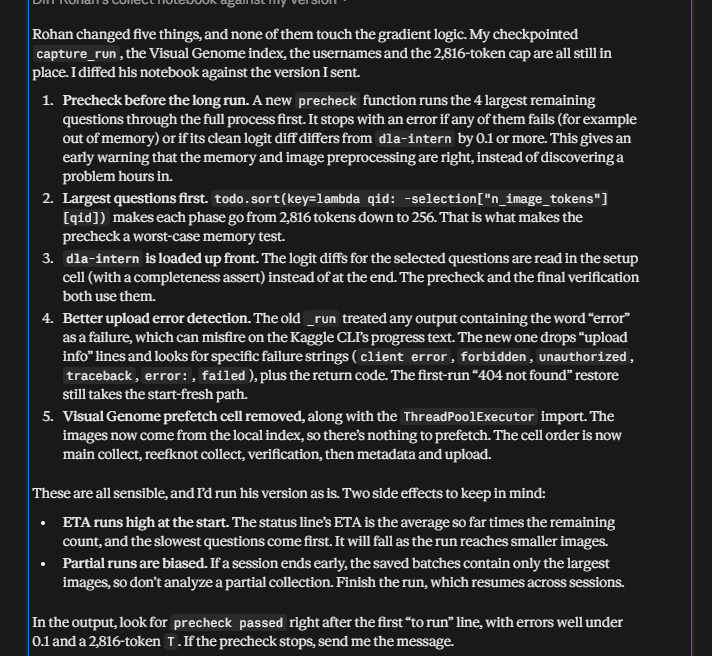

In [4]:
!pip install -q -U transformers accelerate requests

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import json
import glob
import time
import zlib
import subprocess
import requests
import numpy as np
import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
device: cuda


In [5]:
MODEL_NAME = "OpenGVLab/InternVL3-8B-hf"

processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    max_memory={0: "7GiB", 1: "13GiB"},
)
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

ln_f = model.model.language_model.norm
lm_head = model.lm_head
layers = model.model.language_model.layers

n_layer = model.config.text_config.num_hidden_layers
n_head = model.config.text_config.num_attention_heads
hidden_dim = model.config.text_config.hidden_size
head_dim = layers[0].self_attn.o_proj.in_features // n_head
IMAGE_TOKEN_ID = model.config.image_token_id
IMAGE_SEQ = processor.image_seq_length
assert len(layers) == n_layer
print(n_layer, "language model layers,", n_head, "heads,", head_dim, "head dim,", model.config.text_config.num_key_value_heads, "kv heads, image token id", IMAGE_TOKEN_ID, "| tokens per tile", IMAGE_SEQ)

processor_config.json:   0%|          | 0.00/72.0 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/481 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.96k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/6.86k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/781 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie model.language_model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/126 [00:00<?, ?B/s]

28 language model layers, 28 heads, 128 head dim, 4 kv heads, image token id 151667 | tokens per tile 256


In [6]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
OWN_INPUT = "/kaggle/input/datasets/ponishbhatia3"
USERNAME = "ponishbhatia3"
MAX_IMAGE_TOKENS = 2816
FORCE_FRESH = False
AMBER_IMAGE_DIR = "/kaggle/input/datasets/nocturnalnerd18/amber-hallucination/image"
VG_ROOT = "/kaggle/input/datasets/sajjad2goudarzi/the-visual-genome-dataset"
VG_INDEX = {}
for dp, _, fns in os.walk(VG_ROOT):
    for fn in fns:
        if fn.lower().endswith(".jpg"):
            VG_INDEX[fn[:-4]] = os.path.join(dp, fn)
print(len(VG_INDEX), "Visual Genome images indexed")
assert len(VG_INDEX) > 100000, "check VG_ROOT and that the visual genome dataset is attached"

NOISE_LEVELS = [3.0]
GRAD_SCALES = [32.0, 1.0]
GRAD_SCALE = GRAD_SCALES[0]
TAIL_N = 5
GROUPS = ["visual", "text", "tail"]
BATCH_SAVE_SIZE = 200
PRECHECK_N = 4
PRECHECK_TOL = 0.1
OUT_DIR = "/kaggle/working/atp_intern"
os.makedirs(OUT_DIR, exist_ok=True)


def load_image(path):
    return Image.open(path).convert("RGB")


def build_inputs(image, text):
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt_text = processor.apply_chat_template(conversation, add_generation_prompt=True)
    inputs = processor(text=prompt_text, images=image, return_tensors="pt").to(model.device, torch.float16)
    inputs.pop("token_type_ids", None)
    return inputs


def find_vg_image_path(image_id):
    return VG_INDEX.get(str(image_id))


def resolve_image_path(q):
    qid = q["question_id"]
    if qid.startswith("amber_"):
        return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    if qid.startswith("reefknot_"):
        return find_vg_image_path(q["image_id"])
    return None


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2"
question_by_id = {q["question_id"]: q for q in all_questions}

with open(f"{INPUT}/dla-intern/dla_meta.json") as f:
    dla_meta = json.load(f)
YES_IDS, NO_IDS = dla_meta["yes_ids"], dla_meta["no_ids"]
for prefix in YES_IDS:
    yes_words = [processor.tokenizer.decode([i]).strip() for i in YES_IDS[prefix]]
    no_words = [processor.tokenizer.decode([i]).strip() for i in NO_IDS[prefix]]
    print(prefix, YES_IDS[prefix], yes_words, NO_IDS[prefix], no_words)
    assert {w.lower() for w in yes_words} == {"yes"} and {w.lower() for w in no_words} == {"no"}, (yes_words, no_words)
assert set(YES_IDS) == {"amber_", "reefknot_"}, set(YES_IDS)

with open(f"{OWN_INPUT}/atp-intern-selection/selection.json") as f:
    selection = json.load(f)
all_sel = [qid for t in selection["selected"] for qid in selection["selected"][t]]
assert len(all_sel) == len(set(all_sel)) == selection["n_selected"], "attach the latest atp-intern-selection"
print(len(all_sel), "selected questions")
if MAX_IMAGE_TOKENS is not None:
    n_all = len(all_sel)
    n_fy = sum(selection["stratum"][q] == "false_yes" for q in all_sel)
    all_sel = [q for q in all_sel if selection["n_image_tokens"][q] <= MAX_IMAGE_TOKENS]
    n_fy_kept = sum(selection["stratum"][q] == "false_yes" for q in all_sel)
    print(f"image token cap {MAX_IMAGE_TOKENS}: kept {len(all_sel)} of {n_all} questions, false_yes {n_fy_kept} of {n_fy}")
need = {question_by_id[q]["image_id"] for q in all_sel if q.startswith("reefknot_")}
n_miss = sum(str(i) not in VG_INDEX for i in need)
print(len(need), "reefknot images needed,", n_miss, "missing")
assert n_miss == 0, "some reefknot images are not in the visual genome dataset"

dla_ld = {}
sel_set = set(all_sel)
for path in glob.glob(f"{INPUT}/dla-intern/*_batch_*.pt"):
    for e in torch.load(path):
        if e["question_id"] in sel_set:
            dla_ld[e["question_id"]] = float(e["logit_diff"])
print(len(dla_ld), "of", len(all_sel), "selected questions have a dla-intern logit difference")
assert set(dla_ld) == sel_set, "attach the complete dla-intern dataset"


def prep(qid):
    q = question_by_id[qid]
    inputs = build_inputs(load_image(resolve_image_path(q)), q["question_text"])
    ids = inputs["input_ids"]
    T = ids.shape[1]
    vis = ids[0] == IMAGE_TOKEN_ID
    tail = torch.zeros(T, dtype=torch.bool, device=ids.device)
    tail[-TAIL_N:] = True
    text = ~vis & ~tail
    assert int(vis.sum()) == inputs["pixel_values"].shape[0] * IMAGE_SEQ and not bool((vis & tail).any())
    prefix = qid.split("_")[0] + "_"
    return {
        "qid": qid, "T": T, "inputs": inputs, "vis": vis, "yes_ids": YES_IDS[prefix], "no_ids": NO_IDS[prefix],
        "masks": {"visual": vis.float().cpu(), "text": text.float().cpu(), "tail": tail.float().cpu()},
        "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0,
    }

UPLOAD_EVERY = 2
SLUG = f"{USERNAME}/atp-intern-noising"


def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    cleaned = "\n".join(l for l in out.splitlines() if "upload info" not in l.lower()).lower()
    bad = ("client error", "forbidden", "unauthorized", "traceback", "error:", "failed")
    return r.returncode == 0 and not any(x in cleaned for x in bad), out


ok, out = (False, "404 forced fresh start") if FORCE_FRESH else _run(["kaggle", "datasets", "download", "-d", SLUG, "-p", OUT_DIR, "--unzip"])
if ok:
    print("restored", len(glob.glob(os.path.join(OUT_DIR, "*_batch_*.pt"))), "batch files from", SLUG)
else:
    if not any(s_ in out.lower() for s_ in ("404", "403", "not found", "does not exist", "forbidden")):
        raise RuntimeError("download failed for an unrelated reason, refusing to start fresh:\n" + out)
    print("no existing dataset, starting fresh")
dataset_exists = ok

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({"title": "atp-intern-noising", "id": SLUG, "subtitle": "Noising attribution patching effects for InternVL3 yes/no questions",
               "description": "Partial or complete collection, see atp_meta.json.", "licenses": [{"name": "CC0-1.0"}]}, f)


def upload(msg):
    global dataset_exists
    version_cmd = ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", msg]
    create_cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR]
    ok_, out_ = _run(version_cmd if dataset_exists else create_cmd)
    if not ok_ and not dataset_exists:
        ok_, out2 = _run(version_cmd)
        out_ += "\n" + out2
    if ok_:
        dataset_exists = True
        print(f"    [upload ok] {msg}")
    else:
        print(f"    [UPLOAD FAILED, continuing] {out_[-400:]}")
    return ok_

108249 Visual Genome images indexed
amber_ [9454] ['Yes'] [2753] ['No']
reefknot_ [9693, 9454] ['yes', 'Yes'] [2753, 2152] ['No', 'no']
4292 selected questions
image token cap 2816: kept 2430 of 4292 questions, false_yes 975 of 1718
1110 reefknot images needed, 0 missing
2430 of 2430 selected questions have a dla-intern logit difference
no existing dataset, starting fresh


In [7]:
STATE = {"noise": None, "seed": 0, "capture": False, "grad": False, "live": None, "vis": None}


def _layer_pre(l):
    def hook(module, args, kwargs):
        h = args[0] if args else kwargs["hidden_states"]
        changed = False
        if l == 0:
            if STATE["noise"] is not None:
                vis = STATE["vis"]
                h = h.clone()
                x = h[:, vis].float()
                generator = torch.Generator().manual_seed(STATE["seed"])
                noise = torch.randn(x.shape, generator=generator).to(h.device)
                h[:, vis] = (x + noise * x.std() * STATE["noise"]).to(h.dtype)
                changed = True
            if STATE["grad"]:
                h = h.detach().requires_grad_(True)
                changed = True
        if STATE["capture"]:
            STATE["live"]["rp"][l] = h
        if not changed:
            return None
        if args:
            return (h,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs)
        kwargs["hidden_states"] = h
        return args, kwargs
    return hook


def _z_pre(l):
    def hook(module, args):
        if STATE["capture"]:
            STATE["live"]["z"][l] = args[0]
    return hook


def _mlp_fwd(l):
    def hook(module, args, output):
        if STATE["capture"]:
            STATE["live"]["mlp"][l] = output
    return hook


_handles = []
for l, layer in enumerate(layers):
    _handles.append(layer.register_forward_pre_hook(_layer_pre(l), with_kwargs=True))
    _handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_z_pre(l)))
    _handles.append(layer.mlp.register_forward_hook(_mlp_fwd(l)))
print(len(_handles), "hooks registered")

_KW = {}


def _save_kw(module, args, kwargs):
    _KW["args"], _KW["kwargs"] = args, kwargs


layers[0].register_forward_pre_hook(_save_kw, with_kwargs=True)

_FH = {}


def _save_final(module, args):
    _FH["h"] = args[0][0, -1].detach()


ln_f.register_forward_pre_hook(_save_final)

84 hooks registered


In [8]:
def mask_on(p, gname, dev):
    cache = p.setdefault("_mask", {})
    key = (gname, str(dev))
    if key not in cache:
        cache[key] = p["masks"][gname].to(dev)
    return cache[key]


def read_delta(p, out):
    logits = out.logits[0, -1].float()
    return p["sign"] * (logits[p["yes_ids"]].mean() - logits[p["no_ids"]].mean())


def capture_run(p, noise, seed):
    """Memory-light gradient run: forward without a graph, then per-layer recompute for the backward pass."""
    STATE.update(noise=noise, seed=seed, capture=True, grad=False, vis=p["vis"])
    STATE["live"] = {"rp": [None] * n_layer, "z": [None] * n_layer, "mlp": [None] * n_layer}
    with torch.no_grad():
        out = model(**p["inputs"], use_cache=False, logits_to_keep=1)
        delta = float(read_delta(p, out))
    acts = {k: [t.detach() for t in STATE["live"][k]] for k in ("z", "mlp", "rp")}
    kw_args, kw_kwargs, h_last = _KW["args"], _KW["kwargs"], _FH["h"]
    del out
    STATE.update(capture=False, live=None, noise=None)
    with torch.enable_grad():
        hl = h_last.clone().requires_grad_(True)
        logits = lm_head(ln_f(hl.view(1, 1, -1)))[0, -1].float()
        d = p["sign"] * (logits[p["yes_ids"]].mean() - logits[p["no_ids"]].mean())
        g_last = torch.autograd.grad(d * GRAD_SCALE, hl)[0]
    finite = bool(torch.isfinite(g_last).all())
    gz, gm, gr = [None] * n_layer, [None] * n_layer, [None] * n_layer
    g_carry = None
    try:
        for l in range(n_layer - 1, -1, -1):
            STATE.update(capture=True, grad=False, noise=None)
            STATE["live"] = {"rp": [None] * n_layer, "z": [None] * n_layer, "mlp": [None] * n_layer}
            with torch.enable_grad():
                h_in = acts["rp"][l].detach().clone().requires_grad_(True)
                if kw_args:
                    o = layers[l](h_in, *kw_args[1:], **kw_kwargs)
                else:
                    kw2 = dict(kw_kwargs)
                    kw2["hidden_states"] = h_in
                    o = layers[l](**kw2)
                o = o[0] if isinstance(o, tuple) else o
                z_l, m_l = STATE["live"]["z"][l], STATE["live"]["mlp"][l]
                if g_carry is None:
                    go = torch.zeros_like(o)
                    go[0, -1] = g_last.to(o.device, o.dtype)
                else:
                    go = g_carry.to(o.device, o.dtype)
                gz_, gm_, gh_ = torch.autograd.grad(o, [z_l, m_l, h_in], grad_outputs=go)
            gz[l], gm[l], gr[l], g_carry = gz_, gm_, gh_, gh_
            finite = finite and all(bool(torch.isfinite(t).all()) for t in (gz_, gm_, gh_))
            STATE["live"] = None
            del o, z_l, m_l, h_in, go
    finally:
        STATE.update(capture=False, grad=False, live=None, noise=None)
    return {"acts": acts, "grads": {"z": gz, "mlp": gm, "rp": gr}, "delta": delta, "finite": finite}


@torch.no_grad()
def capture_forward(p, noise, seed):
    STATE.update(noise=noise, seed=seed, capture=True, grad=False, vis=p["vis"])
    STATE["live"] = {"rp": [None] * n_layer, "z": [None] * n_layer, "mlp": [None] * n_layer}
    out = model(**p["inputs"], use_cache=False, logits_to_keep=1)
    delta = read_delta(p, out)
    result = {"acts": STATE["live"], "delta": float(delta)}
    STATE.update(capture=False, live=None, noise=None)
    del out
    return result


def atp_effects(A, B, G, p):
    head = torch.zeros(len(GROUPS), n_layer, n_head)
    mlp = torch.zeros(len(GROUPS), n_layer)
    rp = torch.zeros(len(GROUPS), n_layer)
    T = p["T"]
    for l in range(n_layer):
        dz = ((A["z"][l].float() - B["z"][l].float()) * G["z"][l].float() / GRAD_SCALE)[0].view(T, n_head, head_dim).sum(-1)
        dm = ((A["mlp"][l].float() - B["mlp"][l].float()) * G["mlp"][l].float() / GRAD_SCALE)[0].sum(-1)
        dr = ((A["rp"][l].float() - B["rp"][l].float()) * G["rp"][l].float() / GRAD_SCALE)[0].sum(-1)
        for gi, g in enumerate(GROUPS):
            head[gi, l] = (mask_on(p, g, dz.device) @ dz).cpu()
            mlp[gi, l] = (mask_on(p, g, dm.device) @ dm).cpu()
            rp[gi, l] = (mask_on(p, g, dr.device) @ dr).cpu()
    return {"head": head, "mlp": mlp, "rp": rp}


def process_once(p, seed):
    global GRAD_SCALE
    clean, scale_used = None, None
    for scale in GRAD_SCALES:
        GRAD_SCALE = scale
        c = capture_run(p, None, seed)
        if c["finite"] and np.isfinite(c["delta"]):
            clean, scale_used = c, scale
            break
        del c
    if clean is None:
        GRAD_SCALE = GRAD_SCALES[0]
        return None, "clean_nonfinite"
    result, reason = None, "corrupt_nonfinite"
    for noise in NOISE_LEVELS:
        r = capture_forward(p, noise, seed)
        if np.isfinite(r["delta"]):
            eff = atp_effects(r["acts"], clean["acts"], clean["grads"], p)
            if all(bool(torch.isfinite(eff[k]).all()) for k in eff):
                result = {
                    "delta_clean": clean["delta"], "delta_corrupt": r["delta"], "TE": clean["delta"] - r["delta"],
                    "noise_used": noise, "grad_scale_used": scale_used,
                    "head": eff["head"], "mlp": eff["mlp"], "rp": eff["rp"],
                }
                del r
                break
        del r
    GRAD_SCALE = GRAD_SCALES[0]
    del clean
    return result, reason


def process(p, seed):
    for attempt in range(2):
        try:
            return process_once(p, seed)
        except torch.cuda.OutOfMemoryError:
            STATE.update(capture=False, grad=False, live=None, noise=None)
            torch.cuda.empty_cache()
    return None, "oom"

In [9]:
def precheck(todo):
    print(f"precheck on the {min(PRECHECK_N, len(todo))} longest remaining questions (memory and agreement with dla-intern)")
    for qid in todo[:PRECHECK_N]:
        p = prep(qid)
        result, reason = process(p, zlib.crc32(qid.encode()) % (2 ** 31))
        assert result is not None, f"precheck failed on {qid}: {reason} (T {p['T']})"
        err = abs(p["sign"] * result["delta_clean"] - dla_ld[qid])
        print(f"  {qid}: T {p['T']}, clean {p['sign'] * result['delta_clean']:+.3f} vs dla {dla_ld[qid]:+.3f}, err {err:.4f}, TE {result['TE']:+.2f}, grad scale {result['grad_scale_used']}")
        assert err < PRECHECK_TOL, f"clean run differs from dla-intern on {qid}; check the tile cap and preprocessing"
        del p, result
        torch.cuda.empty_cache()
    print("precheck passed")


def collect(tag, keep):
    todo_ids = [qid for qid in all_sel if keep(qid)]
    paths = sorted(glob.glob(os.path.join(OUT_DIR, f"{tag}_batch_*.pt")))
    done_ids = set()
    for path in paths:
        done_ids.update(e["question_id"] for e in torch.load(path))
    todo = [qid for qid in todo_ids if qid not in done_ids]
    todo.sort(key=lambda qid: -selection["n_image_tokens"][qid])
    print(f"{tag}: {len(todo_ids)} questions, {len(done_ids)} already done, {len(todo)} to run")
    if todo:
        precheck(todo)

    batch_entries, batch_index, missing, failed = [], len(paths), 0, 0
    t_start = time.time()

    for i, qid in enumerate(todo):
        q = question_by_id[qid]
        image_path = resolve_image_path(q)
        if image_path is None or not os.path.exists(image_path):
            missing += 1
            continue

        p = prep(qid)
        seed = zlib.crc32(qid.encode()) % (2 ** 31)
        result, reason = process(p, seed)
        entry = {
            "question_id": qid, "image_id": q["image_id"], "hallucination_type": q["hallucination_type"],
            "ground_truth_answer": q["ground_truth_answer"], "stratum": selection["stratum"][qid],
            "group": selection["group"][qid], "source": selection["source"][qid], "split": selection["split"][qid],
            "sign": p["sign"], "seed": seed, "ok": result is not None, "T": p["T"], "n_visual": int(p["vis"].sum()),
        }
        if result is None:
            entry["reason"] = reason
            failed += 1
        else:
            entry.update(result)
            entry["pred_yes"] = bool(p["sign"] * result["delta_clean"] > 0)
        batch_entries.append(entry)
        del p

        if len(batch_entries) >= BATCH_SAVE_SIZE:
            torch.save(batch_entries, os.path.join(OUT_DIR, f"{tag}_batch_{batch_index}.pt"))
            batch_entries, batch_index = [], batch_index + 1
            if batch_index % UPLOAD_EVERY == 0:
                upload(f"{tag}: {batch_index} batches")

        if i % 20 == 0 and i > 0:
            torch.cuda.empty_cache()
            elapsed = time.time() - t_start
            avg = elapsed / (i + 1)
            print(f"[{i + 1}/{len(todo)}] {qid} ({avg:.2f} s/question avg, ETA {avg * (len(todo) - i - 1) / 60:.1f} min, "
                  f"failed {failed}, missing images {missing})", flush=True)

    if batch_entries:
        torch.save(batch_entries, os.path.join(OUT_DIR, f"{tag}_batch_{batch_index}.pt"))
    upload(f"{tag}: done")
    print(f"done -- {tag}, failed {failed}, missing images {missing}, {(time.time() - t_start) / 60:.1f} min")
    return missing

In [10]:
missing = collect("main", lambda qid: not qid.startswith("reefknot_"))
assert missing == 0, f"{missing} questions have no image"

main: 891 questions, 0 already done, 891 to run
precheck on the 4 longest remaining questions (memory and agreement with dla-intern)


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: The AccumulateGrad node's stream does not match the stream of the node that produced the incoming gradient. This may incur unnecessary synchronization and break CUDA graph capture if the AccumulateGrad node's stream is the default stream. This mismatch is caused by an AccumulateGrad node created prior to the current iteration being kept alive. This can happen if the autograd graph is still being kept alive by tensors such as the loss, or if you are using DDP, which will stash a reference to the node. To resolve the mismatch, delete all references to the autograd graph or ensure that DDP initialization is performed under the same stream as subsequent forwards. If the mismatch is intentional, you can use torch.autograd.graph.set_warn_on_accumulate_grad_stream_mismatch(False) to suppress this warning. (Triggered internally at /pytorch/torch/csrc/autograd/input_buffer.cpp:240.)
  return Variable._execution_en

  amber_13834: T 2837, clean +1.828 vs dla +1.828, err 0.0000, TE +2.86, grad scale 32.0
  amber_8580: T 2580, clean +1.578 vs dla +1.578, err 0.0000, TE -2.61, grad scale 32.0
  amber_8080: T 2579, clean +3.922 vs dla +3.922, err 0.0000, TE -1.94, grad scale 32.0
  amber_8524: T 2579, clean -11.328 vs dla -11.328, err 0.0000, TE +10.38, grad scale 32.0
precheck passed
[21/891] amber_7700 (16.82 s/question avg, ETA 243.9 min, failed 0, missing images 0)
[41/891] amber_7520 (14.72 s/question avg, ETA 208.5 min, failed 0, missing images 0)
[61/891] amber_4969 (13.45 s/question avg, ETA 186.0 min, failed 0, missing images 0)
[81/891] amber_5588 (12.81 s/question avg, ETA 173.0 min, failed 0, missing images 0)
[101/891] amber_2965 (12.41 s/question avg, ETA 163.4 min, failed 0, missing images 0)
[121/891] amber_2922 (12.18 s/question avg, ETA 156.3 min, failed 0, missing images 0)
[141/891] amber_6115 (11.99 s/question avg, ETA 149.9 min, failed 0, missing images 0)
[161/891] amber_4499 (1

In [11]:
missing = collect("reefknot", lambda qid: qid.startswith("reefknot_"))
assert missing == 0, f"{missing} questions have no image"

reefknot: 1539 questions, 0 already done, 1539 to run
precheck on the 4 longest remaining questions (memory and agreement with dla-intern)
  reefknot_2408758_1: T 2843, clean -0.367 vs dla -0.367, err 0.0000, TE -1.75, grad scale 32.0
  reefknot_2398044_0: T 2843, clean +3.977 vs dla +3.984, err 0.0078, TE +5.78, grad scale 32.0
  reefknot_2369229_0: T 2843, clean +1.672 vs dla +1.672, err 0.0000, TE +2.48, grad scale 32.0
  reefknot_2317701_3: T 2842, clean -3.328 vs dla -3.328, err 0.0000, TE +2.38, grad scale 32.0
precheck passed
[21/1539] reefknot_2344859_1 (16.59 s/question avg, ETA 419.6 min, failed 0, missing images 0)
[41/1539] reefknot_2327298_0 (13.76 s/question avg, ETA 343.5 min, failed 0, missing images 0)
[61/1539] reefknot_498038_0 (12.77 s/question avg, ETA 314.6 min, failed 0, missing images 0)
[81/1539] reefknot_2328456_1 (12.27 s/question avg, ETA 298.1 min, failed 0, missing images 0)
[101/1539] reefknot_2378754_2 (11.96 s/question avg, ETA 286.7 min, failed 0, miss

In [12]:
entries = []
for path in sorted(glob.glob(os.path.join(OUT_DIR, "*_batch_*.pt"))):
    entries.extend(torch.load(path))
ids = [e["question_id"] for e in entries]
print(f"{len(entries)} entries, {len(set(ids))} unique, {len(set(all_sel) - set(ids))} selected questions missing")
assert set(ids) == set(all_sel) and len(ids) == len(set(ids)), "collection incomplete or duplicated"

good = [e for e in entries if e["ok"]]
bad = [e for e in entries if not e["ok"]]
print(f"ok {len(good)}, failed {len(bad)}", {r: sum(e['reason'] == r for e in bad) for r in {e['reason'] for e in bad}})
print("noise level used:", {n: sum(e["noise_used"] == n for e in good) for n in NOISE_LEVELS})
print("gradient scale used:", {s: sum(e["grad_scale_used"] == s for e in good) for s in GRAD_SCALES})

err = max(abs(e["sign"] * e["delta_clean"] - dla_ld[e["question_id"]]) for e in good)
print(f"clean logit difference vs dla-intern over {len(good)} questions: max err {err:.4f}")
assert err < 0.1, "clean runs differ from the DLA collection"
assert len(bad) <= 0.05 * len(entries), "too many failed questions"

for stratum in ("false_yes", "true_yes", "true_no"):
    sub = [e for e in good if e["stratum"] == stratum]
    te = np.array([e["TE"] for e in sub])
    blind = np.array([e["sign"] * e["delta_corrupt"] for e in sub])
    print(f"{stratum:10s} n {len(sub):5d} | mean TE {te.mean():+.2f} | share with |TE| > 1: {np.mean(np.abs(te) > 1):.2f} | "
          f"mean delta clean {np.mean([e['delta_clean'] for e in sub]):+.2f} | blind Yes minus No {blind.mean():+.2f}")
print("sequence length: min", min(e["T"] for e in good), "max", max(e["T"] for e in good))
print("collection verified")

2430 entries, 2430 unique, 0 selected questions missing
ok 2430, failed 0 {}
noise level used: {3.0: 2430}
gradient scale used: {32.0: 2430, 1.0: 0}
clean logit difference vs dla-intern over 2430 questions: max err 0.0156
false_yes  n   975 | mean TE -2.67 | share with |TE| > 1: 0.81 | mean delta clean -2.29 | blind Yes minus No -0.38
true_yes   n   859 | mean TE +4.01 | share with |TE| > 1: 0.94 | mean delta clean +3.60 | blind Yes minus No -0.41
true_no    n   596 | mean TE +2.92 | share with |TE| > 1: 0.77 | mean delta clean +4.19 | blind Yes minus No -1.26
sequence length: min 275 max 2845
collection verified


In [13]:
with open(os.path.join(OUT_DIR, "atp_meta.json"), "w") as f:
    json.dump({
        "model": MODEL_NAME, "yes_ids": YES_IDS, "no_ids": NO_IDS, "n_layer": n_layer, "n_head": n_head, "groups": GROUPS,
        "tail_n": TAIL_N, "noise_levels": NOISE_LEVELS, "grad_scales": GRAD_SCALES, "direction": "noising",
        "n_ok": len(good), "n_failed": len(bad),
    }, f)

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": "atp-intern-noising",
        "id": f"{USERNAME}/atp-intern-noising",
        "subtitle": "Noising attribution patching effects for InternVL3 yes/no questions",
        "description": "Per-question attribution patching for InternVL3-8B on the questions in atp-intern-selection. "
                       "Corrupt run: Gaussian noise added to the visual embeddings at layer 0 with std noise_used times the std of those embeddings. "
                       "Metric delta is the sign-corrected Yes minus No logit gap at the last position (mean over the Yes, yes variants minus mean over the No, no variants for reefknot, Yes and No for amber), "
                       "positive when the model favours the true answer. "
                       "head [3, 28, 28], mlp [3, 28] and rp [3, 28] hold the first-order effect of replacing each component's clean activation with its corrupt activation, "
                       "(corrupt minus clean) times the gradient of delta at the clean run, in logit units. The first axis is the position group: visual, text, tail (last 5 positions). "
                       "head is the attention head output before o_proj, mlp the MLP output, rp the residual stream entering the layer. "
                       "TE is delta_clean minus delta_corrupt. T and n_visual give the sequence length and image token count. Entries with ok false have no effects.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)

assert upload("final: verified"), "final upload failed"

    [upload ok] final: verified
